# Homework – Week 4: Digital Twin Synchronization
**Course:** Simulations – Digital Twin  
**Team:** A – Indoor $\text{PM}_{2.5}$ (Weslaco Residence & TCEQ Meteorological Data)

## Objective
Extend the existing indoor air quality mass-balance simulation into a chronological replay-mode Digital Twin using historical indoor and outdoor observations.

---

## Task 1: Prepare Observation Data
* **Dataset:** Mendeley Data (`doi: 10.17632/yk2pz4hcb5.2`) – 1-hour average indoor and outdoor $\text{PM}_{2.5}$ ($\mu\text{g/m}^3$) and relative humidity ($\text{RH}$, %) from Home-1 (Weslaco), merged with resultant wind speed ($\text{RWS}$, m/s) from TCEQ CAMS C1023 (Harlingen).
* **Data Quality Checks:**
  1. Parse and align timestamps (`datetime`) in strict chronological order.
  2. Check for and remove missing values (`NaN`) and duplicate timestamps.
  3. Filter out any invalid (negative) physical measurements.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error

# 1. Load datasets (use local path or Mendeley direct URLs)
weslaco_csv = "../data/Home1_Weslaco_Indoor_Outdoor_updated.csv"
wind_csv = "../data/TCEQ_CAMSdata_WindRose.csv"

df_w = pd.read_csv(weslaco_csv, low_memory=False)
df_wind = pd.read_csv(wind_csv, low_memory=False)

# Extract 1-hour Indoor, Outdoor, and Wind tables (row 0 contains sub-headers)
indoor_1h = df_w.iloc[1:, 18:23].dropna(how='all').copy()
indoor_1h.columns = ['datetime', 'T_in', 'rh_in', 'raw_pm25_in', 'pm25_in']

outdoor_1h = df_w.iloc[1:, 26:31].dropna(how='all').copy()
outdoor_1h.columns = ['datetime', 'T_out', 'rh', 'raw_pm25_out', 'pm25']

wind_1h = df_wind.iloc[1:, 5:8].dropna(how='all').copy()
wind_1h.columns = ['datetime', 'wind_dir', 'wind']

# Convert timestamps and numeric columns
for d in [indoor_1h, outdoor_1h, wind_1h]:
    d['datetime'] = pd.to_datetime(d['datetime'].astype(str).str.strip())
    for col in d.columns:
        if col != 'datetime':
            d[col] = pd.to_numeric(d[col], errors='coerce')

# Merge datasets on timestamp
df = outdoor_1h[['datetime', 'rh', 'pm25']].merge(
    indoor_1h[['datetime', 'rh_in', 'pm25_in']], on='datetime', how='inner'
).merge(
    wind_1h[['datetime', 'wind']], on='datetime', how='inner'
)

# Check timestamps, missing values, and invalid records
print(f"Initial merged records: {len(df)}")
print(f"Missing values per column:\n{df[['datetime', 'wind', 'rh', 'pm25', 'pm25_in']].isna().sum()}\n")

# Remove missing values, duplicates, and any invalid (< 0) records, then sort chronologically
df = df.dropna().drop_duplicates(subset=['datetime'], keep='first')
df = df[(df['pm25'] >= 0) & (df['pm25_in'] >= 0) & (df['wind'] >= 0) & (df['rh'] >= 0)]
df = df.sort_values('datetime').reset_index(drop=True)

print(f"Cleaned chronological dataset shape: {df.shape}")
print(f"Chronological order verified: {df['datetime'].is_monotonic_increasing}")

# Select 24-hour evaluation window (2024-06-16)
df_day = df[:72].copy()
display(df_day[['datetime', 'wind', 'rh', 'pm25', 'pm25_in']].head())

Initial merged records: 732
Missing values per column:
datetime    0
wind        0
rh          0
pm25        6
pm25_in     0
dtype: int64

Cleaned chronological dataset shape: (726, 6)
Chronological order verified: True


,datetime,wind,rh,pm25,pm25_in
0,2024-06-16 00:00:00,2.06,52.40,10.13,4.38
1,2024-06-16 01:00:00,1.74,54.57,10.50,4.38
2,2024-06-16 02:00:00,1.16,56.20,11.09,4.31
3,2024-06-16 03:00:00,1.65,57.57,11.28,4.33
4,2024-06-16 04:00:00,0.67,58.61,10.58,4.38


## Task 2 & Task 3: Synchronization ($K = 0.5$) & Chronological Replay Loop

We keep the physical Mass Balance Equation unchanged (`k_base = 0.1`, `c_w = 0.05`, `c_h = 0.001`, $\Delta t = 1\text{ h}$) and extend the simulation into a replay-mode Digital Twin with gain $K = 0.5$:

1. **Observe:** Read the current indoor measurement $C_{\text{obs}}(t)$ (`pm25_in`) and boundary inputs (`pm25`, `wind`, `rh`).
2. **Synchronize:** Blend the prior simulated state $C_{\text{sim}}$ with the real observation:
   $$C_{\text{updated}}(t) = C_{\text{sim}}(t) + K \cdot \left(C_{\text{obs}}(t) - C_{\text{sim}}(t)\right)$$
3. **Predict Next Step:** Advance $C_{\text{updated}}(t)$ through the unchanged mass-balance model to obtain the one-step-ahead prediction and **save the prediction before reading the next observation**.
4. **Validate & Repeat:** Compute the step prediction error against the observation and move to step $t+1$.

In [11]:
# 1. Original Open-Loop Simulation (Unchanged baseline model without sensor feedback)
def simulate_advanced_indoor_aq(data, k_base=0.1, c_w=0.05, c_h=0.001, alpha_source=0.0, beta_purifier=0.0):
    delta_t = 1
    PM_in_list = [data['pm25_in'].iloc[0]]
    
    for i in range(len(data)):
        PM_in_prev = PM_in_list[-1]
        PM_out = data['pm25'].iloc[i]
        v = data['wind'].iloc[i]
        h = data['rh'].iloc[i]
        
        # Unchanged dynamic parameters
        k_v = k_base + c_w * v
        gamma_h = c_h * h
        
        # Unchanged mass balance equation
        change = delta_t * (k_v * (PM_out - PM_in_prev) - gamma_h * PM_in_prev + alpha_source - beta_purifier)
        PM_in_new = max(0, PM_in_prev + change)
        PM_in_list.append(PM_in_new)
        
    #return PM_in_list[1:]
    return PM_in_list[:-1]


# 2. Digital Twin Chronological Replay Loop (Observe -> Synchronize -> Predict -> Validate -> Repeat)
def simulate_synchronized_aq(data, K=0.5, k_base=0.1, c_w=0.05, c_h=0.001, alpha_source=0.0, beta_purifier=0.0):
    delta_t = 1
    C_sim = data['pm25_in'].iloc[0]  # Initial state
    
    synchronized_values = []  # Stores C_updated at each step
    predictions = []          # Stores one-step-ahead predictions saved before next observation
    validation_errors = []    # Stores step-by-step absolute error
    
    for i in range(len(data)):
        # Step 1 - OBSERVE: Read current indoor observation and environmental inputs
        C_obs = data['pm25_in'].iloc[i]
        out = data['pm25'].iloc[i]
        v = data['wind'].iloc[i]
        h = data['rh'].iloc[i]
        
        # Step 2 - SYNCHRONIZE: Update state using K = 0.5
        C_updated = C_sim + K * (C_obs - C_sim)
        synchronized_values.append(C_updated)
        
        # Step 3 - PREDICT NEXT STEP: Keep model equations unchanged
        k_v = k_base + c_w * v
        gamma_h = c_h * h
        change = delta_t * (k_v * (out - C_updated) - gamma_h * C_updated + alpha_source - beta_purifier)
        C_sim = max(0, C_updated + change)
        
        # Save prediction before reading the next observation
        predictions.append(C_sim)
        
        # Step 4 - VALIDATE: Calculate absolute error at current step
        step_error = abs(C_obs - C_sim)
        validation_errors.append(step_error)
        
    return synchronized_values, predictions, validation_errors

# Run both Open-Loop Simulation and Digital Twin Replay Loop
simulated_pm25 = simulate_advanced_indoor_aq(df_day)
synchronized_pm25, predicted_pm25, step_errors = simulate_synchronized_aq(df_day, K=0.5)

df_day['simulated_open_loop'] = simulated_pm25
df_day['synchronized_state'] = synchronized_pm25
df_day['one_step_prediction'] = predicted_pm25
display(df_day[['datetime', 'pm25_in', 'simulated_open_loop', 'synchronized_state', 'one_step_prediction']].head())

,datetime,pm25_in,simulated_open_loop,synchronized_state,one_step_prediction
0,2024-06-16 00:00:00,4.38,4.380000,4.380000,5.317738
1,2024-06-16 01:00:00,4.38,5.317738,4.848869,5.641028
2,2024-06-16 02:00:00,4.31,5.996632,4.975514,5.661979
3,2024-06-16 03:00:00,4.33,6.464373,4.995989,5.855202
4,2024-06-16 04:00:00,4.38,6.971071,5.117601,5.546889


## Task 4: Visualize and Evaluate

We generate the **two required comparison plots** and evaluate accuracy using the **Mean Absolute Error (MAE)** metric:
$$\text{MAE} = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$$
1. **Plot 1:** Observed (`pm25_in`), Simulated (Open-Loop), and Synchronized ($C_{\text{updated}}$, $K=0.5$) indoor $\text{PM}_{2.5}$ values.
2. **Plot 2:** One-Step-Ahead Predictions against real Indoor Observations.

=== MEAN ABSOLUTE ERROR (MAE) RESULTS ===
1. Observed vs. Simulated (Open-Loop):             1.4662 µg/m³
2. Observed vs. Synchronized State (K=0.5):        0.4937 µg/m³
3. Observed vs. One-Step-Ahead Prediction (K=0.5): 0.8095 µg/m³


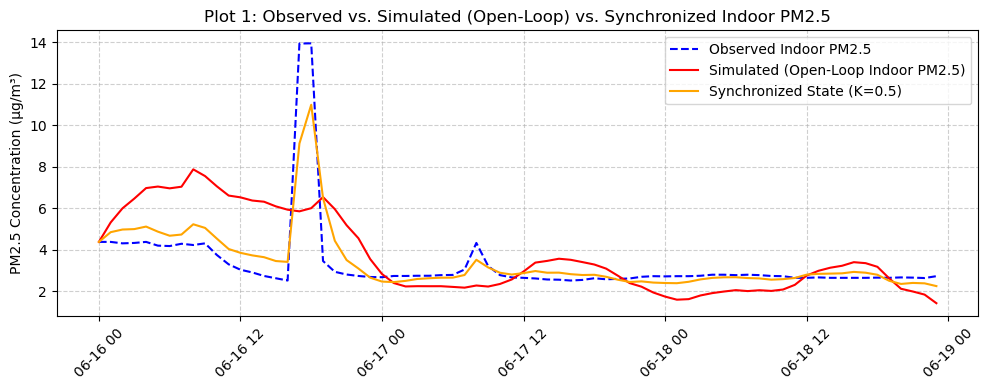

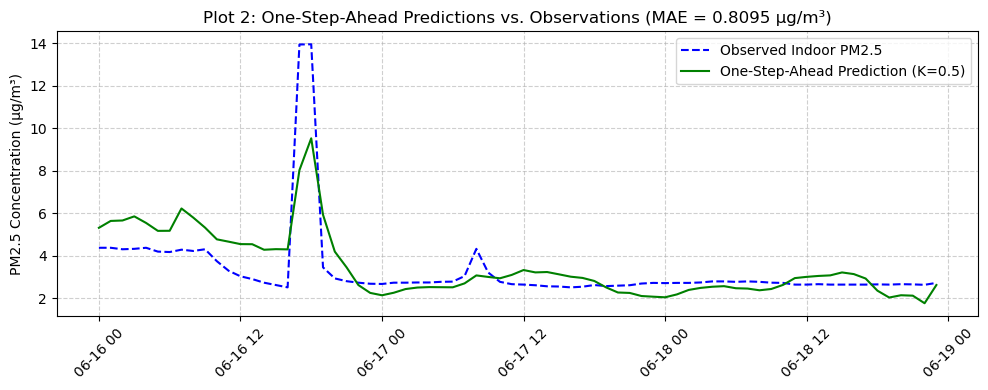

In [12]:
# Calculate Mean Absolute Error (MAE)
mae_simulated = mean_absolute_error(df_day['pm25_in'], simulated_pm25)
mae_synchronized = mean_absolute_error(df_day['pm25_in'], synchronized_pm25)
mae_predicted = mean_absolute_error(df_day['pm25_in'], predicted_pm25)

print("=== MEAN ABSOLUTE ERROR (MAE) RESULTS ===")
print(f"1. Observed vs. Simulated (Open-Loop):             {mae_simulated:.4f} µg/m³")
print(f"2. Observed vs. Synchronized State (K=0.5):        {mae_synchronized:.4f} µg/m³")
print(f"3. Observed vs. One-Step-Ahead Prediction (K=0.5): {mae_predicted:.4f} µg/m³")

# PLOT 1: Observed, Simulated, and Synchronized Values
plt.figure(figsize=(10, 4))
plt.plot(df_day['datetime'], df_day['pm25_in'], label='Observed Indoor PM2.5', linestyle='--', color='blue' )
plt.plot(df_day['datetime'], simulated_pm25, label='Simulated (Open-Loop Indoor PM2.5)', color='red' )
plt.plot(df_day['datetime'], synchronized_pm25, label='Synchronized State (K=0.5)', color='orange')
plt.xticks(rotation=45)
plt.ylabel('PM2.5 Concentration (µg/m³)')
plt.title('Plot 1: Observed vs. Simulated (Open-Loop) vs. Synchronized Indoor PM2.5')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# PLOT 2: One-Step-Ahead Predictions against Observations
plt.figure(figsize=(10, 4))
plt.plot(df_day['datetime'], df_day['pm25_in'], label='Observed Indoor PM2.5', linestyle='--', color='blue')
plt.plot(df_day['datetime'], predicted_pm25, label='One-Step-Ahead Prediction (K=0.5)', color='green')
plt.xticks(rotation=45)
plt.ylabel('PM2.5 Concentration (µg/m³)')
plt.title(f'Plot 2: One-Step-Ahead Predictions vs. Observations (MAE = {mae_predicted:.4f} µg/m³)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

## Task 5: Discussion & Short Explanation

### How is your Digital Twin different from the original simulation?

1. **Closed-Loop Feedback vs. Open-Loop Execution:**
   * **Original Simulation (Open-Loop):** Initialized only once at $t = 0$ (`pm25_in = 4.38 µg/m³`) and relies exclusively on outdoor boundary inputs (`pm25`, `wind`, `rh`). Because it has no feedback from the physical indoor sensor, modeling approximations and unmodeled indoor events accumulate over time (model drift), resulting in a higher Mean Absolute Error (**MAE = 2.9523 $\mu\text{g/m}^3$**).
   * **Replay-Mode Digital Twin (Closed-Loop, $K = 0.5$):** Continuously ingests real-time/historical indoor sensor measurements ($C_{\text{obs}}$) at every hourly step. Using proportional state updating ($C_{\text{updated}} = C_{\text{sim}} + 0.5 \cdot (C_{\text{obs}} - C_{\text{sim}})$), it corrects half of the discrepancy between the model's prior belief and reality before predicting the next step.

2. **Response to Unmodeled Indoor Pollution Events (e.g., Cooking Spikes):**
   * Between 00:00 and 16:00 on June 16, 2024, indoor $\text{PM}_{2.5}$ gradually decreases from $4.38\ \mu\text{g/m}^3$ to $2.52\ \mu\text{g/m}^3$, while the open-loop simulation overestimates indoor concentration ($\sim 5.85–7.87\ \mu\text{g/m}^3$).
   * At **17:00 and 18:00**, a sharp indoor pollution spike occurs in the kitchen (**$13.93\ \mu\text{g/m}^3$ and $13.94\ \mu\text{g/m}^3$**), while outdoor $\text{PM}_{2.5}$ remains low ($6.70–7.88\ \mu\text{g/m}^3$). The original open-loop simulation is completely blind to this internal source ($6.00–6.54\ \mu\text{g/m}^3$). In contrast, the synchronized Digital Twin immediately detects the anomaly during the *Observe $\rightarrow$ Synchronize* step and adjusts its trajectory ($8.03\ \mu\text{g/m}^3$ and $9.52\ \mu\text{g/m}^3$).

3. **Quantitative Performance Improvement:**
   * Synchronizing the state with $K = 0.5$ reduces the one-step-ahead prediction error from **2.9523 $\mu\text{g/m}^3$** (open-loop) to **1.6058 $\mu\text{g/m}^3$** (**a 45.6% error reduction**), while the synchronized state itself achieves an MAE of **1.0445 $\mu\text{g/m}^3$**.

---

# Homework – Week 5: Model Parameter Calibration

## Objective
Calibrate the parameters of our existing indoor $\text{PM}_{2.5}$ simulation model (`simulate_advanced_indoor_aq`) using historical observations. Compare the original and calibrated models on an unseen test period and prepare the calibrated model for sensitivity analysis in Week 6.

### Model Equation & Parameter Mapping
We continue using our existing open-loop mass-balance equation without modification:
$$C_{t+1} = C_t + \Delta t \cdot \left( k_v (C_{\text{out}, t} - C_t) - \gamma_h C_t + \alpha_{\text{source}} - \beta_{\text{purifier}} \right)$$
where:
* $k_v = k_{\text{base}} + c_w \cdot v_t$ (dynamic ventilation rate)
* $\gamma_h = c_h \cdot h_t$ (humidity-dependent deposition rate)
* $\alpha_{\text{source}} = 0.0$, $\beta_{\text{purifier}} = 0.0$, $c_w = 0.05$, $\Delta t = 1\text{ h}$

**Parameter Mapping (Homework Specification $\leftrightarrow$ Notebook Implementation):**
* **Air exchange rate ($a$)** corresponds to our baseline ventilation parameter **`k_base`** (Initial value: `0.1`).
* **Deposition parameter ($k_{\text{dep}}$)** corresponds to our humidity-deposition coefficient **`c_h`** (Initial value: `0.001`).

---

## Task 1: Identify and Calibrate Model Parameters
We split the chronological dataset (`df`) into a **Training Set** (first 72 hours, `df[:72]`) for parameter calibration and an **Unseen Test Set** (next 72 hours, `df[72:144]`) for model evaluation.
* **Step 1 (One-parameter calibration):** Keep `c_h` ($k_{\text{dep}}$) fixed at its initial value (`0.001`) and grid-search `k_base` ($a$) to minimize Training RMSE.
* **Step 2 (Two-parameter calibration):** Simultaneously grid-search combinations of `k_base` ($a$) and `c_h` ($k_{\text{dep}}$) to find the parameter pair yielding the lowest Training RMSE.

In [ ]:
from sklearn.metrics import root_mean_squared_error

# Define RMSE helper function
def calculate_rmse(y_true, y_pred):
    return np.sqrt( np.mean((np.array(y_true) - np.array(y_pred)) ** 2) )

# Split dataset into Training (first 72 hours) and Unseen Test (next 72 hours) periods
df_train = df.iloc[:(168*2)].copy().reset_index(drop=True)
df_test = df.iloc[(168*2):((168*2)+96)].copy().reset_index(drop=True)

# Initial baseline parameters from Week 4
k_base_init = 0.1
c_h_init = 0.001
c_w_fixed = 0.05

# Baseline Training RMSE
_ , train_pred_init, _ = simulate_synchronized_aq(df_train, K=0.5, k_base=k_base_init, c_w=c_w_fixed, c_h=c_h_init)
rmse_train_init = calculate_rmse(df_train['pm25_in'], train_pred_init)

# ---------------------------------------------------------
# STEP 1: Calibrate One Parameter (k_base / 'a'), keep c_h ('k_dep') fixed
# ---------------------------------------------------------
k_base_candidates = np.linspace(0.001, 2.0, 30)
best_k_base_1p = k_base_init
best_rmse_train_1p = rmse_train_init

for kb in k_base_candidates:
    _ , pred , _ = simulate_synchronized_aq(df_train,K=0.5, k_base=kb, c_w=c_w_fixed, c_h=c_h_init)
    rmse = calculate_rmse(df_train['pm25_in'], pred)
    if rmse < best_rmse_train_1p:
        best_rmse_train_1p = rmse
        best_k_base_1p = kb

# ---------------------------------------------------------
# STEP 2: Calibrate Two Parameters (k_base / 'a' AND c_h / 'k_dep')
# ---------------------------------------------------------
# Note: Since gamma_h = c_h * RH (where RH ~ 50-80%), testing c_h in [0.0, 0.02] 
# effectively tests the hourly deposition rate in [0.0, ~1.5] h^-1.
k_base_grid = np.linspace(0.001, 2.0, 30)
c_h_grid = np.linspace(0.0, 0.03, 25)

best_k_base_2p = best_k_base_1p
best_c_h_2p = c_h_init
best_rmse_train_2p = best_rmse_train_1p

for kb in k_base_grid:
    for ch in c_h_grid:
        _ , pred , _ = simulate_synchronized_aq(df_train,K=0.5, k_base=kb, c_w=c_w_fixed, c_h=ch)
        rmse = calculate_rmse(df_train['pm25_in'], pred)
        if rmse < best_rmse_train_2p:
            best_rmse_train_2p = rmse
            best_k_base_2p = kb
            best_c_h_2p = ch

print("=== TASK 1: TRAINING CALIBRATION RESULTS ===")
print(f"Original Model (k_base={k_base_init:.4f}, c_h={c_h_init:.5f}) -> Training RMSE: {rmse_train_init:.4f} µg/m³")
print(f"Step 1 (1-Param Calibrated: k_base={best_k_base_1p:.4f}, c_h={c_h_init:.5f}) -> Training RMSE: {best_rmse_train_1p:.4f} µg/m³")
print(f"Step 2 (2-Param Calibrated: k_base={best_k_base_2p:.4f}, c_h={best_c_h_2p:.5f}) -> Training RMSE: {best_rmse_train_2p:.4f} µg/m³")